# 03 · Validación temporal y pronóstico con ML

**Objetivo:** ver por qué la validación cruzada aleatoria falla en series de tiempo, y comparar
las dos estrategias para pronosticar varios pasos con un modelo de ML: **recursiva** (realimentar
predicciones) y **directa** (rezagos ≥ horizonte).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

from common import set_seed, setup_style

setup_style()
rng = set_seed(42)
co2 = (
    sm.datasets.co2.load_pandas().data["co2"].resample("MS").mean().interpolate()
)  # mensual, 1958–2001
from applied_ts.evaluation import rolling_origin
from applied_ts.features import lag_features
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import KFold, TimeSeriesSplit, cross_val_score

# Serie sintética “horaria”: ciclo diario + tendencia que cambia de régimen + ruido AR(1)
n = 24 * 120
t = np.arange(n)
trend = np.where(t < n * 0.6, 0.01 * t, 0.01 * n * 0.6 - 0.02 * (t - n * 0.6))
noise = np.zeros(n)
for i in range(1, n):
    noise[i] = 0.7 * noise[i - 1] + rng.normal(0, 3)
y = pd.Series(
    50 + trend + 15 * np.sin(2 * np.pi * t / 24) + noise,
    index=pd.date_range("2024-01-01", periods=n, freq="h"),
)

## 1. K-fold aleatorio vs. validación temporal

Mismo modelo y mismos features. K-fold mezcla pasado y futuro: entrena con datos posteriores al
punto que evalúa, y en una serie con autocorrelación y cambios de régimen eso es una fuga.

In [2]:
X = lag_features(y, [1, 2, 3, 24, 48], rolling=[24]).dropna()
target = y.loc[X.index]
model = HistGradientBoostingRegressor(max_iter=200, random_state=0)
scores = {
    "K-fold aleatorio": -cross_val_score(
        model,
        X,
        target,
        cv=KFold(5, shuffle=True, random_state=0),
        scoring="neg_mean_absolute_error",
    ),
    "TimeSeriesSplit": -cross_val_score(
        model, X, target, cv=TimeSeriesSplit(5), scoring="neg_mean_absolute_error"
    ),
}
for name, s in scores.items():
    print(f"{name:<18} MAE = {s.mean():.2f} ± {s.std():.2f}")

K-fold aleatorio   MAE = 2.83 ± 0.12
TimeSeriesSplit    MAE = 3.09 ± 0.26


El K-fold aleatorio es más optimista (MAE menor, y con menos dispersión), pero en esta serie la
diferencia es moderada (~9 %), y una parte se debe a que los primeros folds de `TimeSeriesSplit`
entrenan con menos datos. La razón de fondo para no usarlo no es solo el número: el K-fold evalúa
un escenario imposible (entrenar con el futuro) y no detecta modelos que se degradan cuando la
serie cambia de régimen. El procedimiento de evaluación debe imitar cómo se usará el modelo.

## 2. Pronóstico a 24 pasos: recursivo vs. directo

- **Recursivo:** un modelo a un paso (rezagos 1, 2, 3, 24…); para la hora 2 se usa la predicción
  de la hora 1 como si fuera real, y así sucesivamente.
- **Directo:** un modelo con rezagos ≥ 24; predice cualquier hora de las próximas 24 con datos
  ya observados, sin realimentar.

recursivo  MAE h=1: 2.96  h=6: 3.43  h=24: 5.49  media: 5.29
directo    MAE h=1: 4.01  h=6: 4.13  h=24: 4.68  media: 4.65


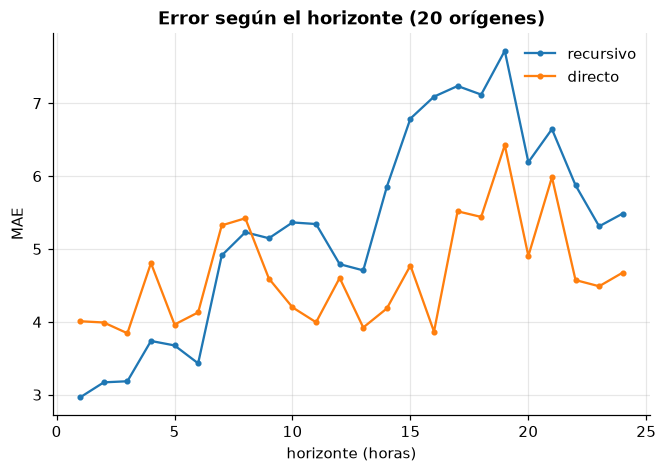

In [3]:
H = 24
rec_feats = lag_features(y, [1, 2, 3, 24, 48])
dir_feats = lag_features(y, [24, 25, 26, 48, 168], min_lag=24)
errors = {"recursivo": [], "directo": []}
for train_idx, test_idx in rolling_origin(n, initial=n - 24 * 20, horizon=H, step=H):
    origin = y.index[test_idx[0]]
    hist = y.iloc[train_idx]
    Xr = rec_feats.iloc[train_idx].dropna()
    rec = HistGradientBoostingRegressor(max_iter=200, random_state=0).fit(Xr, hist.loc[Xr.index])
    Xd = dir_feats.iloc[train_idx].dropna()
    direct = HistGradientBoostingRegressor(max_iter=200, random_state=0).fit(Xd, hist.loc[Xd.index])
    # recursivo: extender la serie con sus propias predicciones
    ext = hist.copy()
    preds = []
    for k in range(H):
        ts = origin + pd.Timedelta(hours=k)
        row = pd.DataFrame(
            {f"lag_{lag}": [ext.iloc[-lag]] for lag in (1, 2, 3, 24, 48)}, index=[ts]
        )
        p = rec.predict(row)[0]
        preds.append(p)
        ext.loc[ts] = p
    actual = y.iloc[test_idx].to_numpy()
    errors["recursivo"].append(np.abs(np.array(preds) - actual))
    errors["directo"].append(np.abs(direct.predict(dir_feats.iloc[test_idx]) - actual))

fig, ax = plt.subplots()
for name, e in errors.items():
    ax.plot(range(1, H + 1), np.mean(e, axis=0), "o-", ms=3, label=name)
ax.set(xlabel="horizonte (horas)", ylabel="MAE", title="Error según el horizonte (20 orígenes)")
ax.legend()
for name, e in errors.items():
    m = np.mean(e, axis=0)
    print(
        f"{name:<10} MAE h=1: {m[0]:.2f}  h=6: {m[5]:.2f}  h=24: {m[-1]:.2f}  media: {m.mean():.2f}"
    )

- **Recursivo gana en horizontes cortos** (h = 1: 2.96 frente a 4.01): usa la información más reciente.
- **Su error crece con el horizonte** (5.49 en h = 24) porque cada paso realimenta errores anteriores.
- **El directo es casi plano** (4.0 → 4.7): no acumula, pero para h = 1 renuncia a saber qué pasó
  hace una hora. En promedio sobre las 24 horas gana el directo (4.65 frente a 5.29).
- Híbridos comunes: un modelo directo por tramo de horizonte, o recursivo solo para las primeras horas.

## Para llevar

- En series de tiempo, validar siempre hacia adelante (origen móvil / `TimeSeriesSplit`).
- Los rezagos convierten el pronóstico en un problema tabular, pero hay que fijar qué se sabe en
  el momento del pronóstico.
- Recursivo: un modelo, error que se acumula. Directo: sin acumulación, pero renuncia a la
  información más reciente para horizontes cortos. El proyecto usa la estrategia directa.